## Analysis Examples

### Plot Averaged PSD with Error Bands


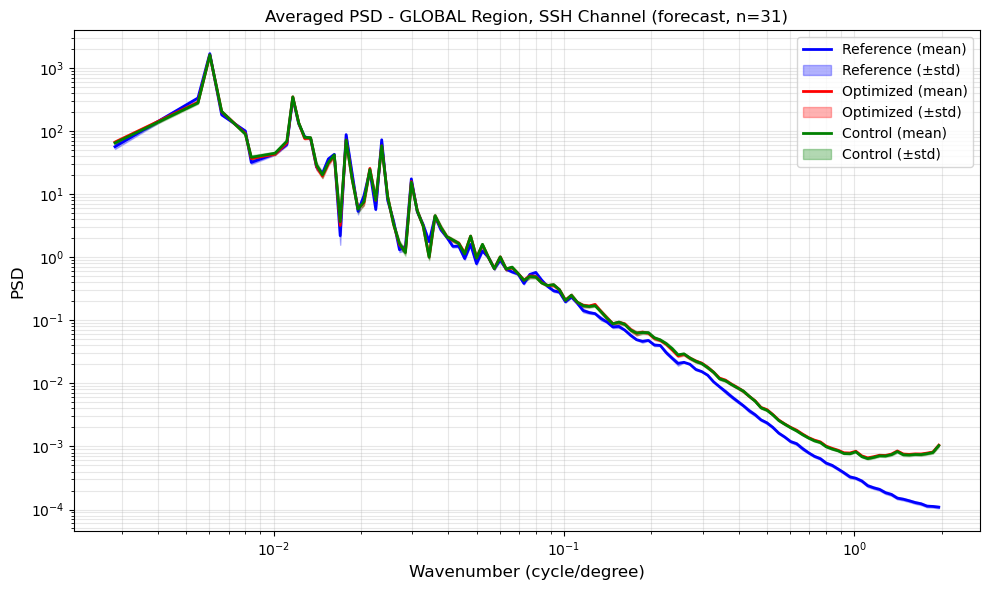

In [6]:
import json
import matplotlib.pyplot as plt
import numpy as np

# Load averaged data
with open('/Odyssey/private/j25lee/glonet/gradient_descent_optimic/outputs/forecast_exp/averaged_psd_forecast.json') as f:
    avg_data = json.load(f)

# Plot for a specific region and channel
region = 'global'
channel = 'SSH'

sample = avg_data[region][channel]
suffix = None
for candidate in ('forecast', 'ic'):
    if f"reference_{candidate}" in sample and f"optimized_{candidate}" in sample:
        suffix = candidate
        break
if suffix is None:
    raise KeyError(f"No reference/optimized keys found in {region}/{channel}")

ref_ic = sample[f"reference_{suffix}"]
opt_ic = sample[f"optimized_{suffix}"]
ctl_ic = sample.get(f"control_{suffix}")

fig, ax = plt.subplots(figsize=(10, 6))

k_ref = np.array(ref_ic['wavenumber'])
p_ref_mean = np.array(ref_ic['power_mean'])
p_ref_std = np.array(ref_ic['power_std'])

k_opt = np.array(opt_ic['wavenumber'])
p_opt_mean = np.array(opt_ic['power_mean'])
p_opt_std = np.array(opt_ic['power_std'])

# Plot with error bands
ax.loglog(k_ref, p_ref_mean, 'b-', linewidth=2, label='Reference (mean)')
ax.fill_between(k_ref, p_ref_mean - p_ref_std, p_ref_mean + p_ref_std, 
                 alpha=0.3, color='blue', label='Reference (±std)')

ax.loglog(k_opt, p_opt_mean, 'r-', linewidth=2, label='Optimized (mean)')
ax.fill_between(k_opt, p_opt_mean - p_opt_std, p_opt_mean + p_opt_std, 
                 alpha=0.3, color='red', label='Optimized (±std)')

if ctl_ic is not None:
    k_ctl = np.array(ctl_ic['wavenumber'])
    p_ctl_mean = np.array(ctl_ic['power_mean'])
    p_ctl_std = np.array(ctl_ic['power_std'])
    ax.loglog(k_ctl, p_ctl_mean, 'g-', linewidth=2, label='Control (mean)')
    ax.fill_between(k_ctl, p_ctl_mean - p_ctl_std, p_ctl_mean + p_ctl_std, 
                    alpha=0.3, color='green', label='Control (±std)')

ax.set_xlabel('Wavenumber (cycle/degree)', fontsize=12)
ax.set_ylabel('PSD', fontsize=12)
ax.set_title(f"Averaged PSD - {region.upper()} Region, {channel} Channel ({suffix}, n={ref_ic['n_samples']})")
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

### Compare Statistics Across Channels

In [5]:
import numpy as np

# Create summary table
regions = list(avg_data.keys())
channels = ['SSH', 'thetao', 'so', 'uo', 'vo']

for region in regions:
    print(f"\n{'='*60}")
    print(f"REGION: {region.upper()}")
    print(f"{'='*60}")
    
    for channel in channels:
        if channel not in avg_data[region]:
            continue
        sample = avg_data[region][channel]
        suffixes = []
        for candidate in ('forecast', 'ic'):
            if any(k in sample for k in (f"reference_{candidate}", f"optimized_{candidate}", f"control_{candidate}")):
                suffixes.append(candidate)
        if not suffixes:
            print(f"{channel:10s}: missing forecast/ic keys")
            continue
        
        for suffix in suffixes:
            parts = []
            ref_key = f"reference_{suffix}"
            opt_key = f"optimized_{suffix}"
            ctl_key = f"control_{suffix}"
            if ref_key in sample:
                ref_ic = sample[ref_key]
                ref_power_mean = np.mean(ref_ic['power_mean'])
                parts.append(f"Ref={ref_power_mean:.2e}")
            if opt_key in sample:
                opt_ic = sample[opt_key]
                opt_power_mean = np.mean(opt_ic['power_mean'])
                parts.append(f"Opt={opt_power_mean:.2e}")
            if ctl_key in sample:
                ctl_ic = sample[ctl_key]
                ctl_power_mean = np.mean(ctl_ic['power_mean'])
                parts.append(f"Ctl={ctl_power_mean:.2e}")
            print(f"{channel:10s} ({suffix}): {', '.join(parts)}")


REGION: GLOBAL
SSH        (forecast): Ref=3.01e+01, Opt=2.90e+01, Ctl=2.91e+01
thetao     (forecast): Ref=2.34e+04, Opt=2.41e+04, Ctl=2.42e+04
so         (forecast): Ref=5.79e+02, Opt=5.00e+02, Ctl=4.94e+02
uo         (forecast): Ref=2.17e+00, Opt=2.21e+00, Ctl=2.23e+00
vo         (forecast): Ref=2.98e-01, Opt=2.00e-01, Ctl=2.06e-01

REGION: GULF_STREAM
SSH        (forecast): Ref=6.84e-02, Opt=6.67e-02, Ctl=6.92e-02
thetao     (forecast): Ref=1.76e+01, Opt=2.18e+01, Ctl=2.16e+01
so         (forecast): Ref=1.27e+00, Opt=1.19e+00, Ctl=1.15e+00
uo         (forecast): Ref=4.71e-03, Opt=3.00e-03, Ctl=3.09e-03
vo         (forecast): Ref=5.85e-03, Opt=3.32e-03, Ctl=3.64e-03

REGION: HIGH_VAR
SSH        (forecast): Ref=3.09e-01, Opt=3.56e-01, Ctl=3.55e-01
thetao     (forecast): Ref=1.25e+02, Opt=1.27e+02, Ctl=1.28e+02
so         (forecast): Ref=2.89e+01, Opt=2.82e+01, Ctl=2.81e+01
uo         (forecast): Ref=2.16e-02, Opt=1.72e-02, Ctl=1.79e-02
vo         (forecast): Ref=9.65e-03, Opt=5.46e-03

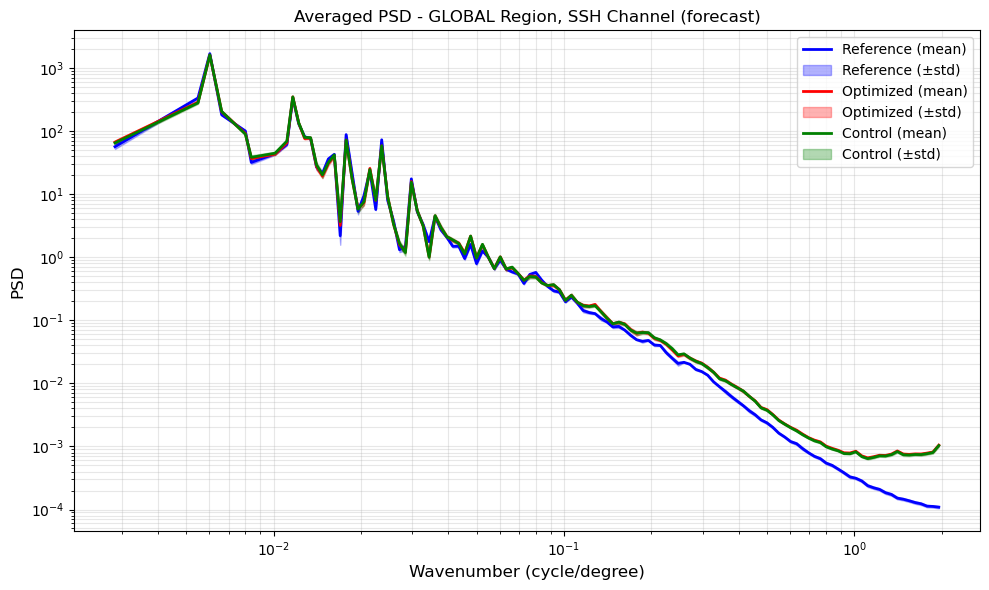

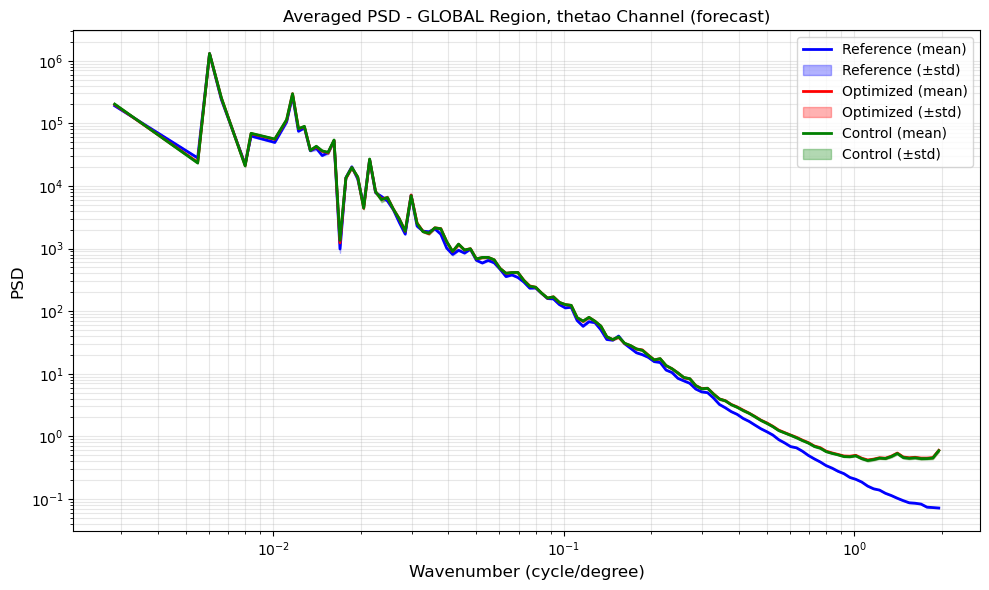

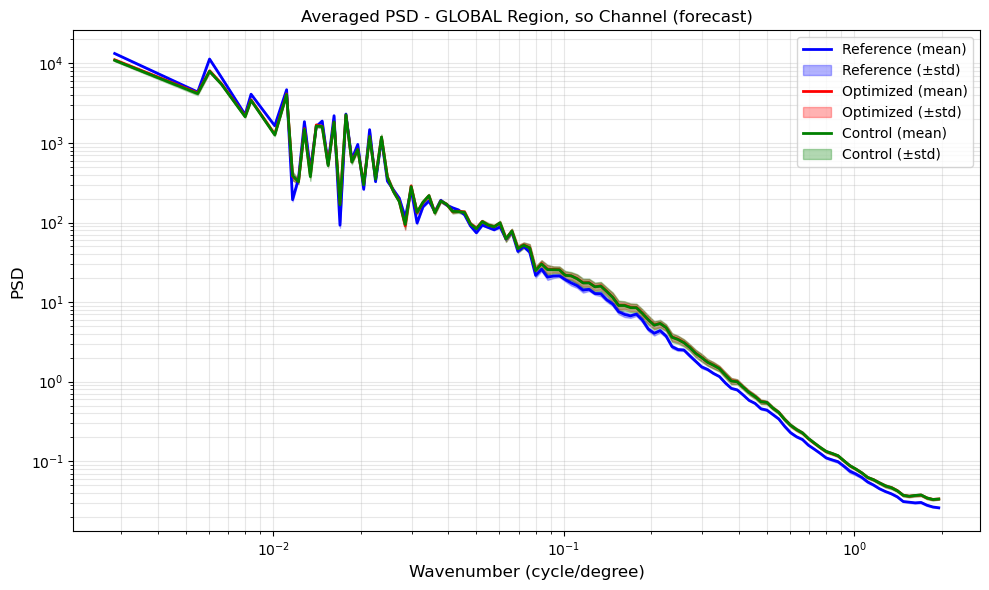

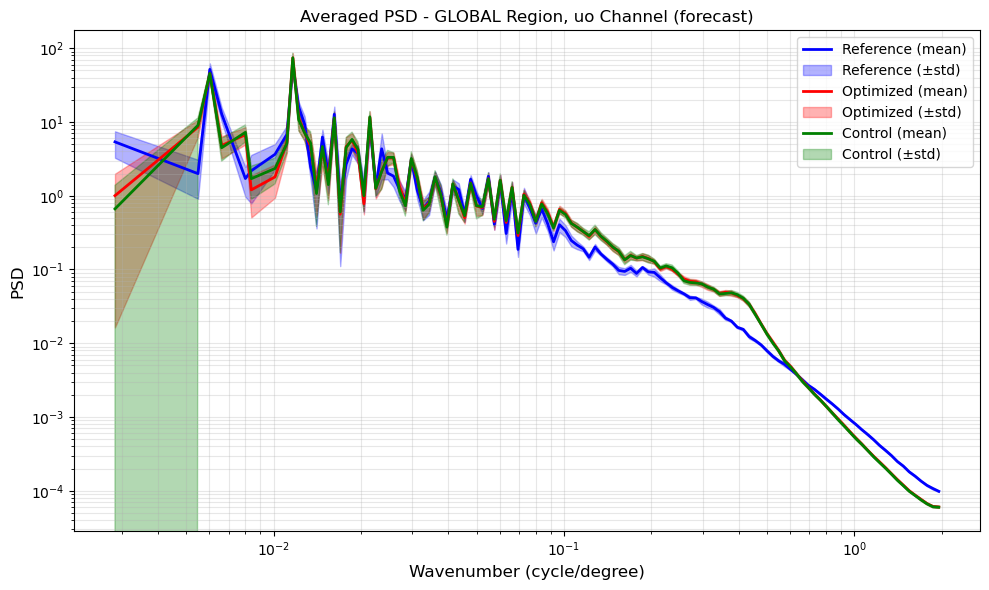

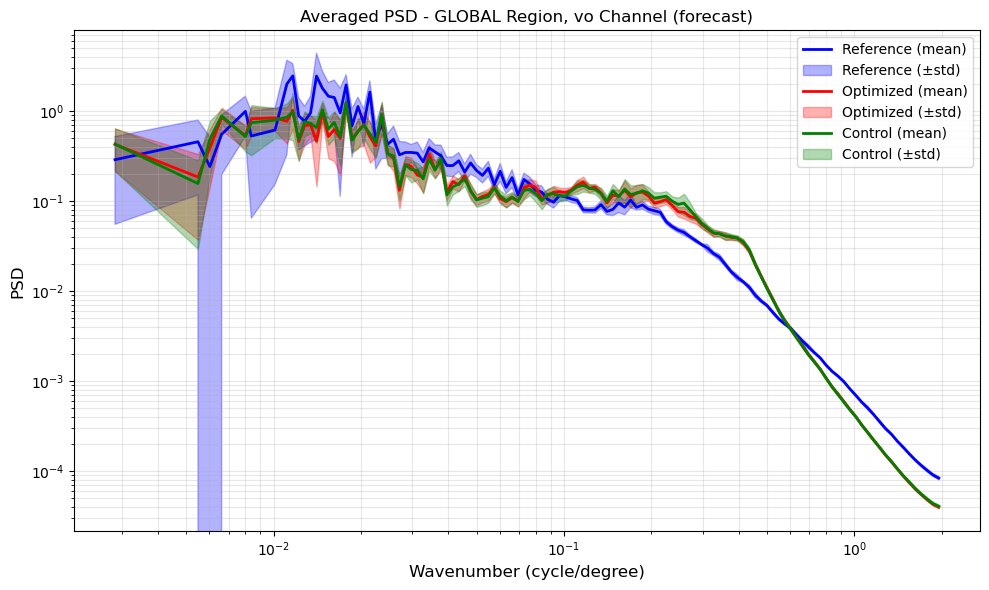

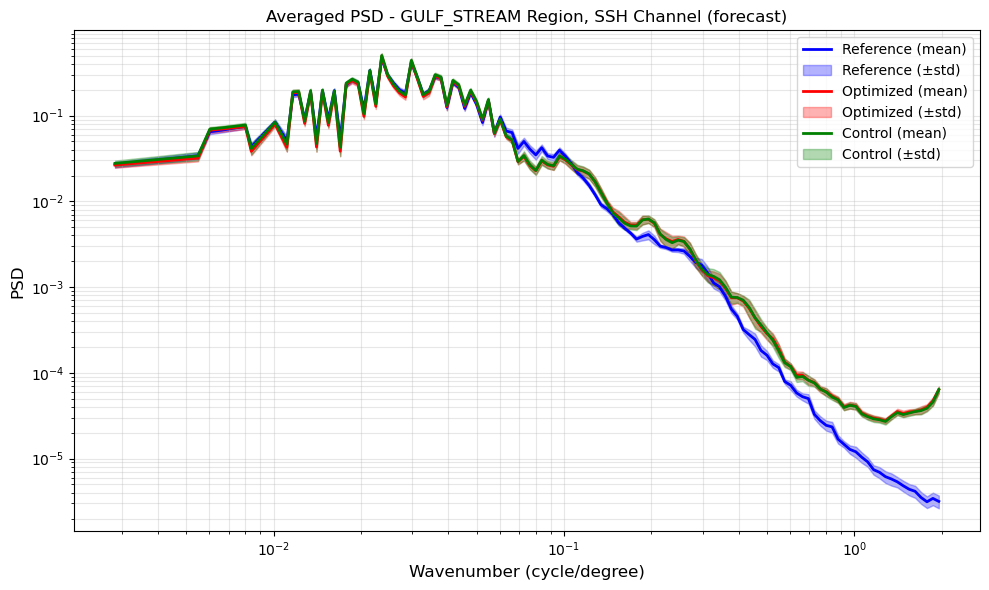

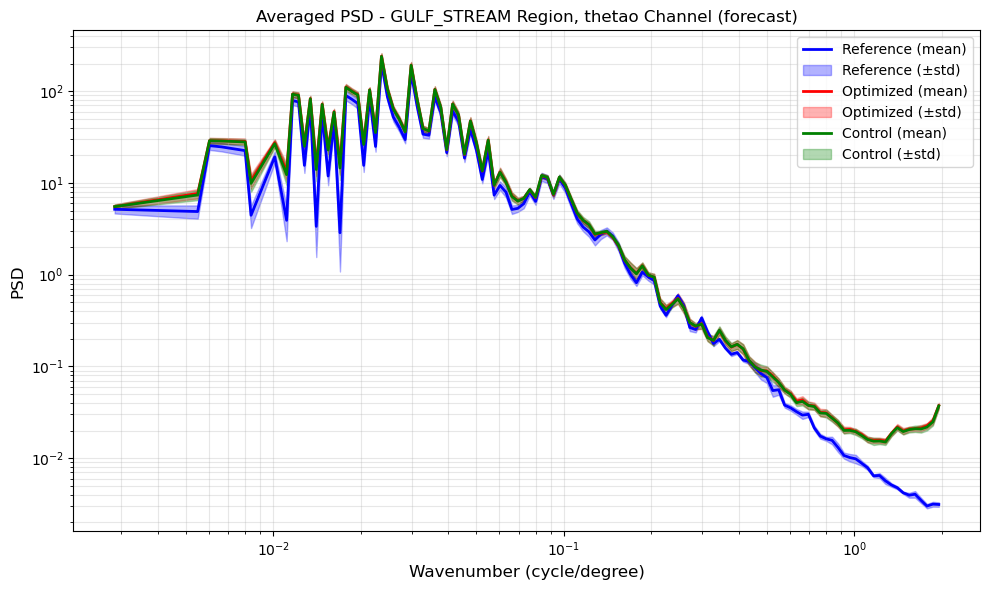

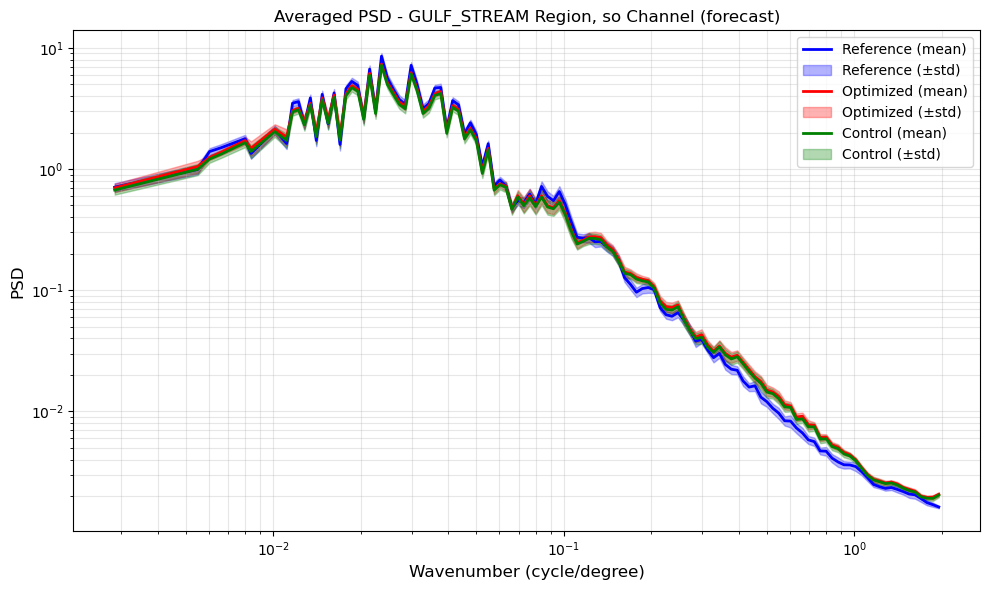

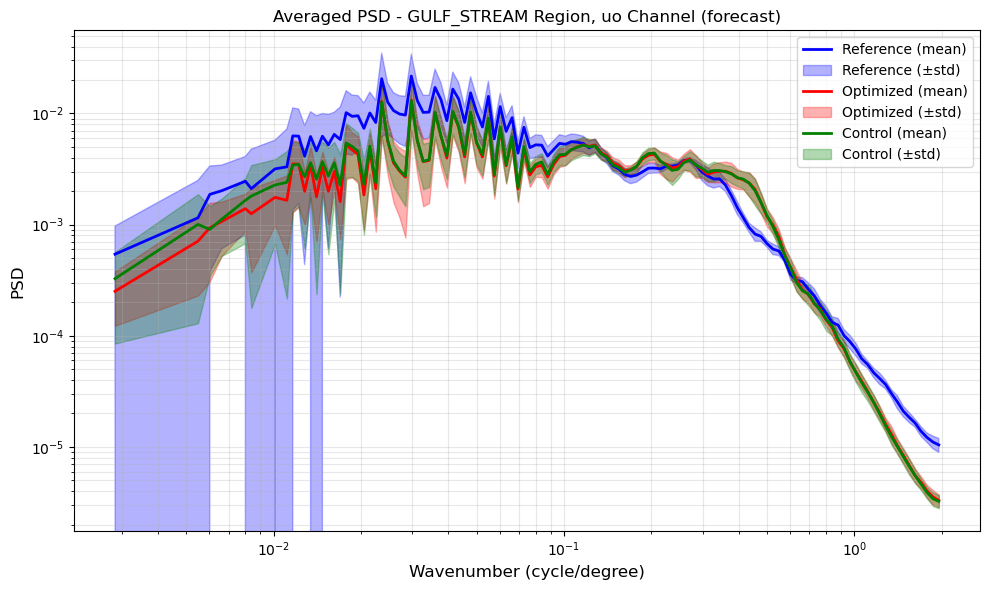

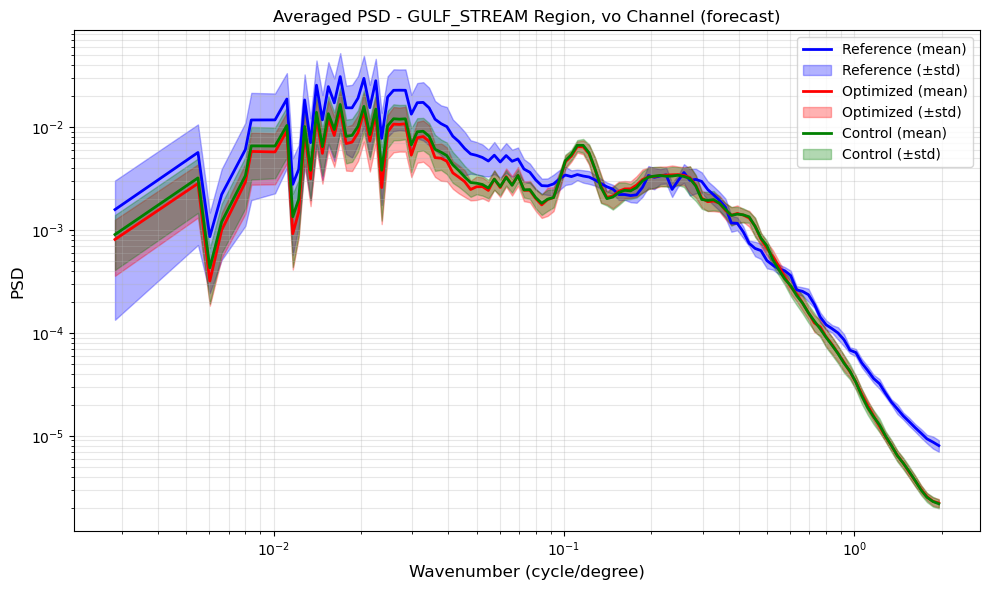

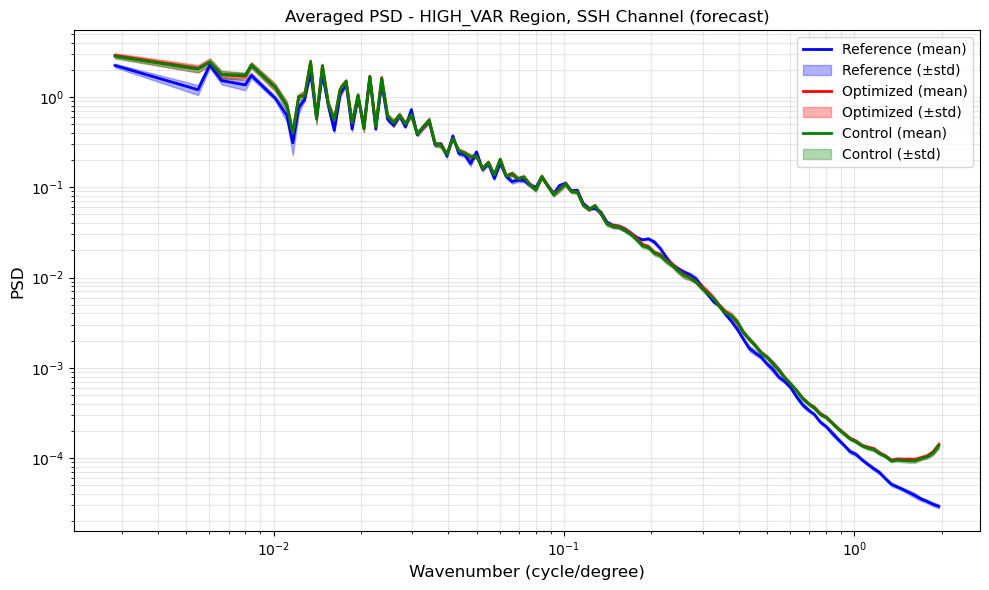

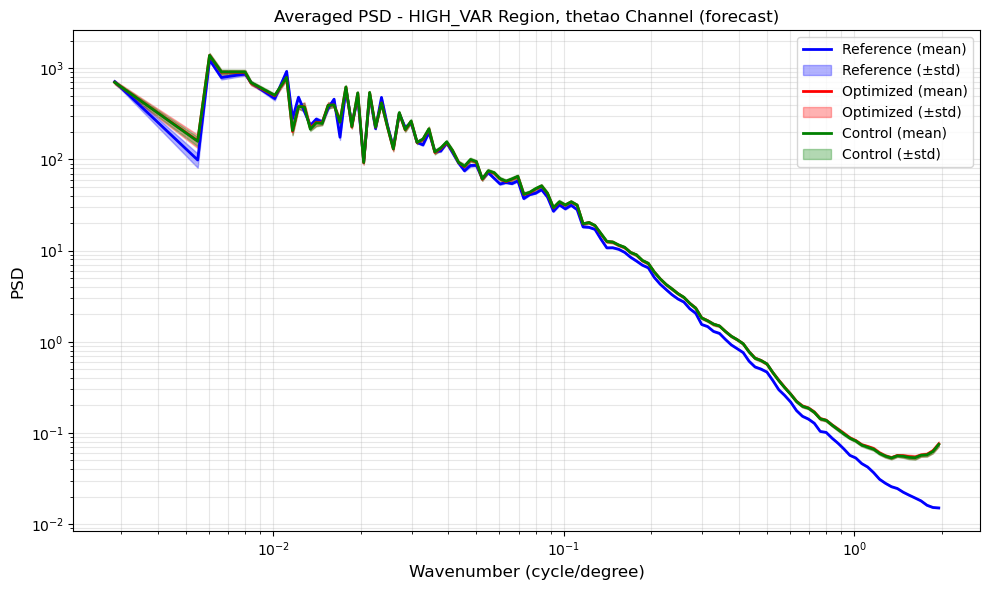

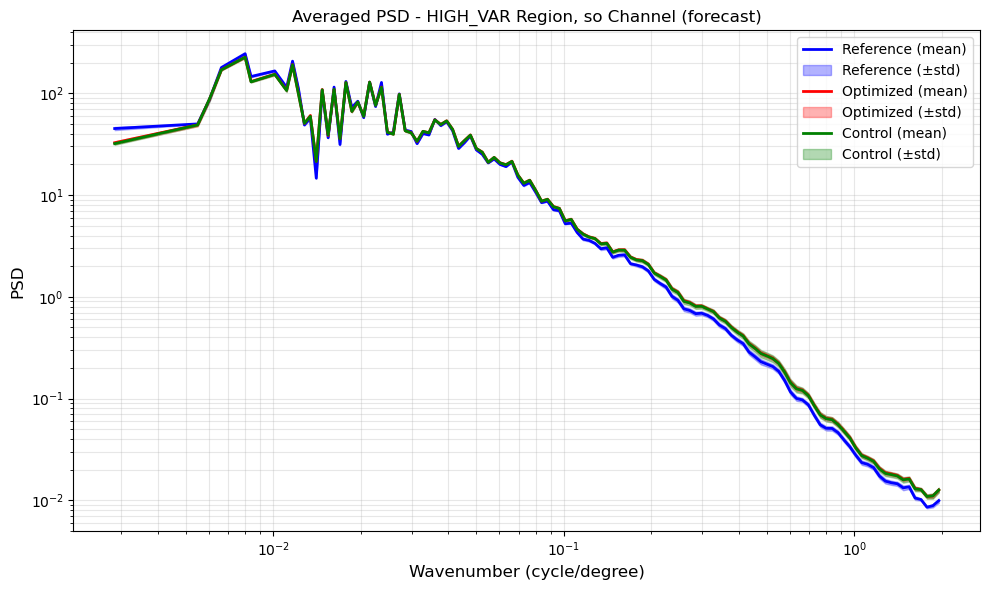

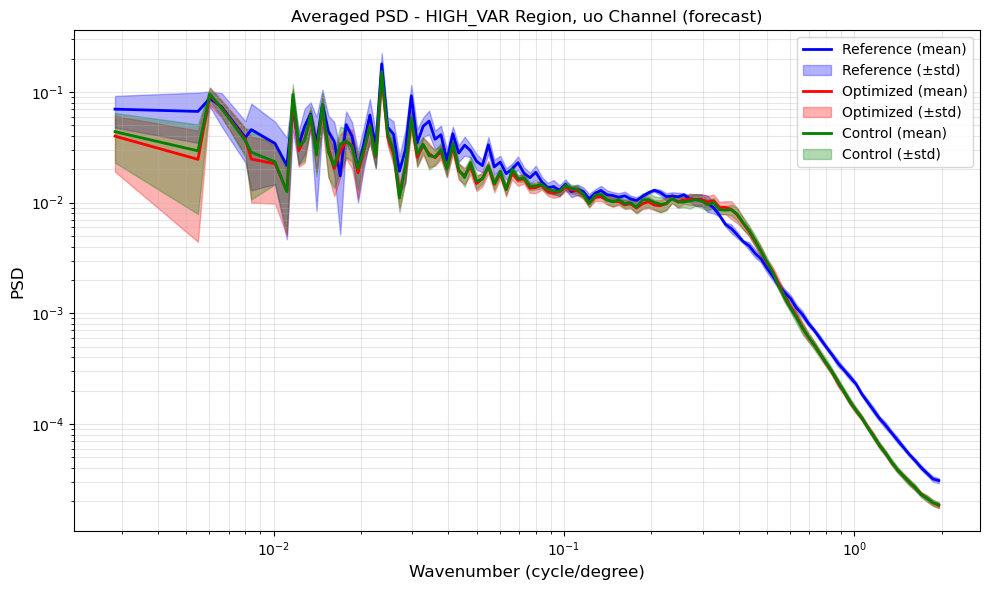

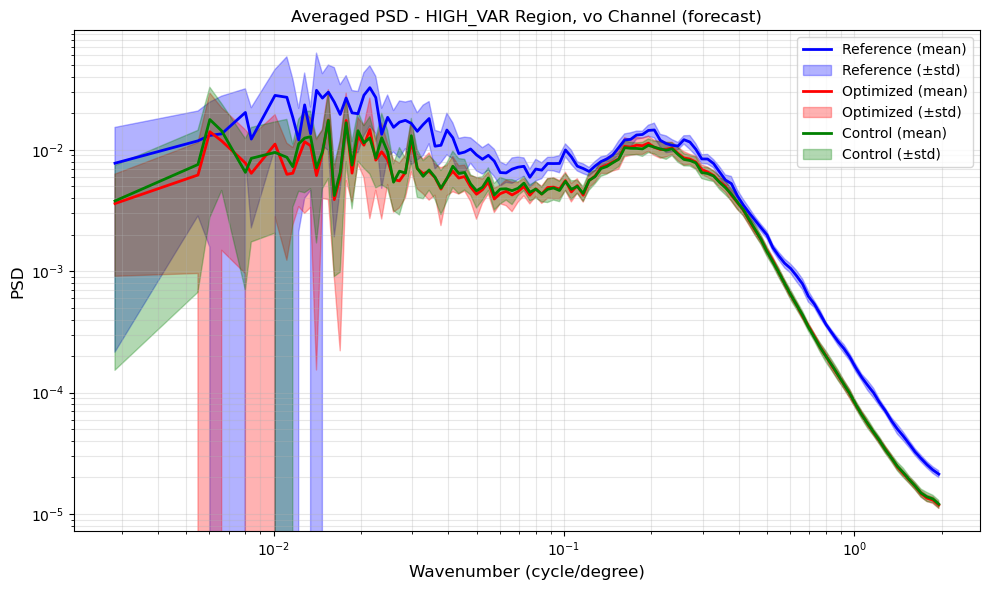

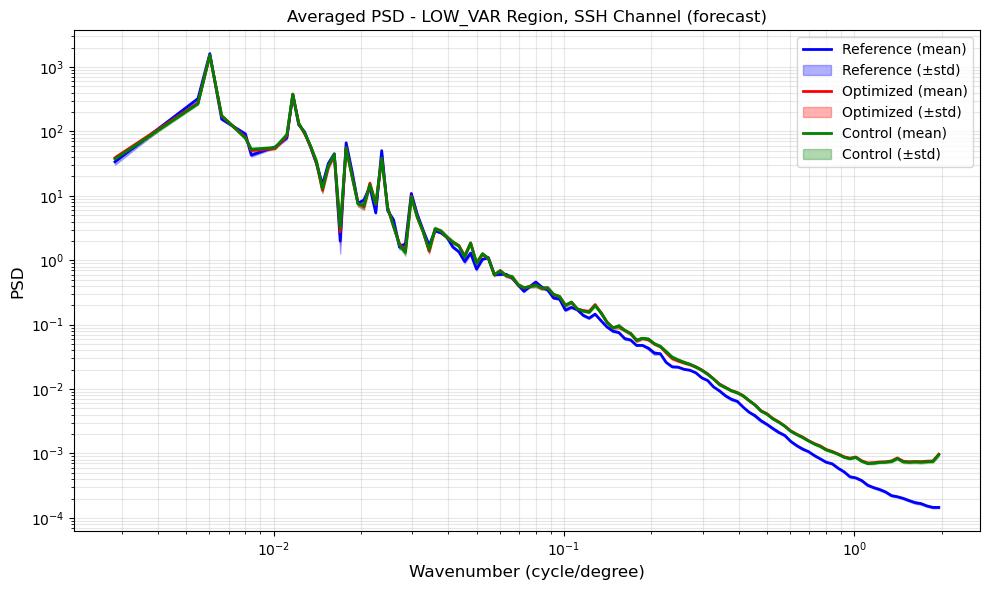

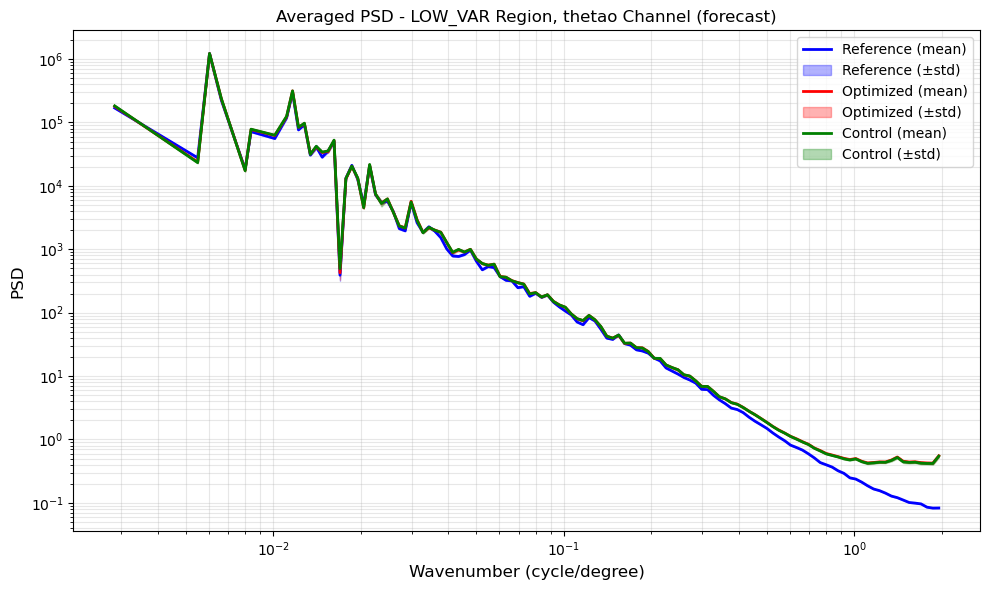

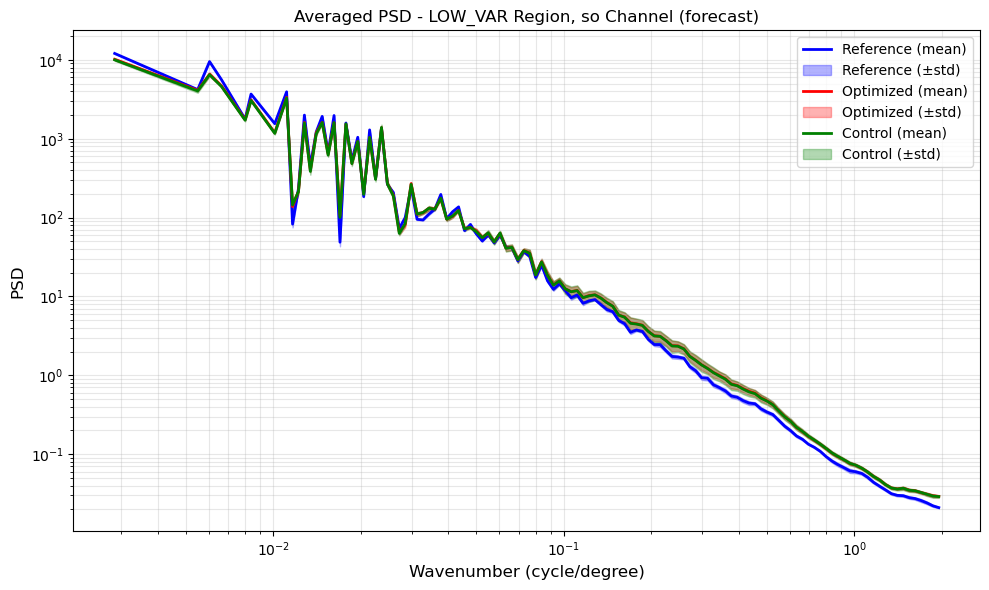

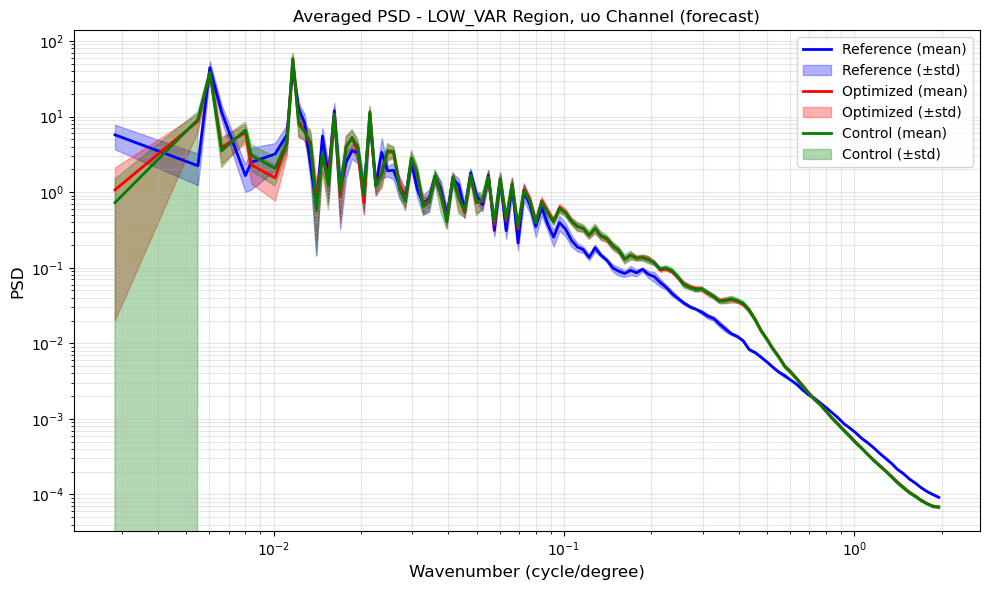

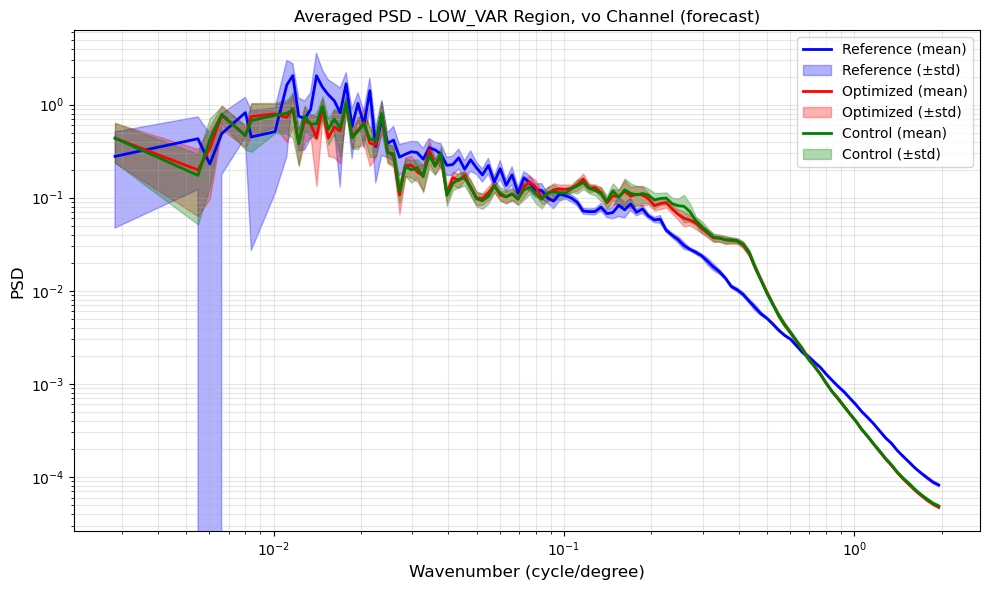

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Plot PSD for every region/channel/suffix available
channels = ['SSH', 'thetao', 'so', 'uo', 'vo']
for region in avg_data:
    for channel in channels:
        if channel not in avg_data[region]:
            continue
        sample = avg_data[region][channel]
        for suffix in ('forecast', 'ic'):
            if not any(k in sample for k in (f"reference_{suffix}", f"optimized_{suffix}", f"control_{suffix}")):
                continue
            fig, ax = plt.subplots(figsize=(10, 6))
            for label, key, color in (
                ('Reference', f"reference_{suffix}", 'blue'),
                ('Optimized', f"optimized_{suffix}", 'red'),
                ('Control', f"control_{suffix}", 'green'),
            ):
                if key not in sample:
                    continue
                data = sample[key]
                k = np.array(data['wavenumber'])
                p_mean = np.array(data['power_mean'])
                p_std = np.array(data['power_std'])
                ax.loglog(k, p_mean, color=color, linewidth=2, label=f"{label} (mean)")
                ax.fill_between(k, p_mean - p_std, p_mean + p_std, alpha=0.3, color=color, label=f"{label} (±std)")
            ax.set_xlabel('Wavenumber (cycle/degree)', fontsize=12)
            ax.set_ylabel('PSD', fontsize=12)
            ax.set_title(f"Averaged PSD - {region.upper()} Region, {channel} Channel ({suffix})")
            ax.grid(True, which='both', alpha=0.3)
            ax.legend(fontsize=10)
            plt.tight_layout()
            plt.show()